# 02 乘客属性、消费行为与预测目标的关系
对应任务：**分析乘客属性、消费行为与预测目标的关系**
做法：把每个特征按取值分组，看各组的 `Transported=True` 比例
（即"被传送的概率"）和样本量。**只看比率不看样本量会骗人**，所以两列一起给。
缺失值在这里被当作一个**独立类别** `__缺失__` 展示——
这样能直接看出"缺失本身是否携带信息"，而不是靠猜。



In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplcache"))

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import preprocess as pp

matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
matplotlib.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

train = pp.build_features(pp.load_raw()[0])
TARGET = pp.TARGET
print("样本量:", len(train), "| 整体目标率: %.4f" % train[TARGET].mean())




样本量: 8693 | 整体目标率: 0.5036


In [2]:
def target_rate(df, col, target=TARGET, min_n=1):
    """按 col 的取值统计目标率与样本量；缺失作为独立类别展示。"""
    s = df[col]
    # 先转 object 再填：可空布尔(boolean)列不接受字符串填充值
    s = s.astype(object).fillna("__缺失__")
    g = (df.assign(_cat=s)
           .groupby("_cat", observed=True)[target]
           .agg(目标率="mean", 人数="size"))
    g["目标率"] = g["目标率"].round(4)
    g["相对整体"] = (g["目标率"] / df[target].mean()).round(2)
    return g.sort_values("目标率", ascending=False)


def rate_table(df, cols, target=TARGET):
    """把多个分类变量的目标率拼成一张总表，便于一眼扫完。"""
    parts = []
    for c in cols:
        t = target_rate(df, c, target).reset_index().rename(columns={"_cat": "取值"})
        t.insert(0, "变量", c)
        parts.append(t)
    return pd.concat(parts, ignore_index=True)




## 2.1 目标变量分布
题目用 Accuracy 评价，前提是类别均衡。先确认这一点。



Transported
True(被传送)    4378
False        4315

正例率 = 0.5036  -> 两类几乎各占一半，Accuracy 是合理指标
全预测 True 的基准分 = 0.5036（这就是要超过的下限）


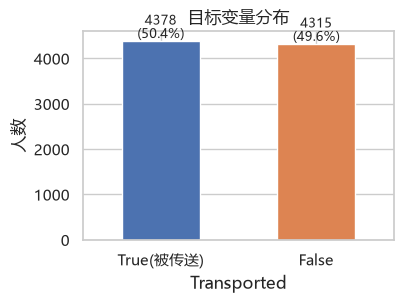

In [3]:
vc = train[TARGET].value_counts().rename({True: "True(被传送)", False: "False"})
print(vc.to_string())
print("\n正例率 = %.4f  -> 两类几乎各占一半，Accuracy 是合理指标"
      % train[TARGET].mean())
print("全预测 True 的基准分 = %.4f（这就是要超过的下限）" % train[TARGET].mean())

fig, ax = plt.subplots(figsize=(4.2, 3.2))
vc.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("目标变量分布")
ax.set_ylabel("人数")
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v}\n({v/len(train)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "02_target_distribution.png", dpi=140, bbox_inches="tight")
plt.show()



## 2.2 分类属性与目标的关系
逐个看：出发星球、目的地、舱位牌面/侧、冷冻睡眠、VIP、年龄段、最大消费项。
**注意看 `__缺失__` 那一行的目标率**——如果它接近整体目标率 0.5036，
说明缺失是随机的；如果明显偏离，说明缺失本身有信息。



In [4]:
cat_cols = ["HomePlanet", "Destination", "Deck", "Side", "CryoSleep", "VIP",
            "AgeBand", "MaxAmenity"]
tbl = rate_table(train, cat_cols)
print(tbl.to_string(index=False))



         变量            取值    目标率   人数  相对整体
 HomePlanet        Europa 0.6588 2131  1.31
 HomePlanet          Mars 0.5230 1759  1.04
 HomePlanet        __缺失__ 0.5124  201  1.02
 HomePlanet         Earth 0.4239 4602  0.84
Destination   55 Cancri e 0.6100 1800  1.21
Destination        __缺失__ 0.5055  182  1.00
Destination PSO J318.5-22 0.5038  796  1.00
Destination   TRAPPIST-1e 0.4712 5915  0.94
       Deck             B 0.7343  779  1.46
       Deck             C 0.6801  747  1.35
       Deck             G 0.5162 2559  1.02
       Deck        __缺失__ 0.5025  199  1.00
       Deck             A 0.4961  256  0.99
       Deck             F 0.4399 2794  0.87
       Deck             D 0.4331  478  0.86
       Deck             E 0.3573  876  0.71
       Deck             T 0.2000    5  0.40
       Side             S 0.5550 4288  1.10
       Side        __缺失__ 0.5025  199  1.00
       Side             P 0.4513 4206  0.90
  CryoSleep          True 0.8176 3037  1.62
  CryoSleep        __缺失__ 0.4885

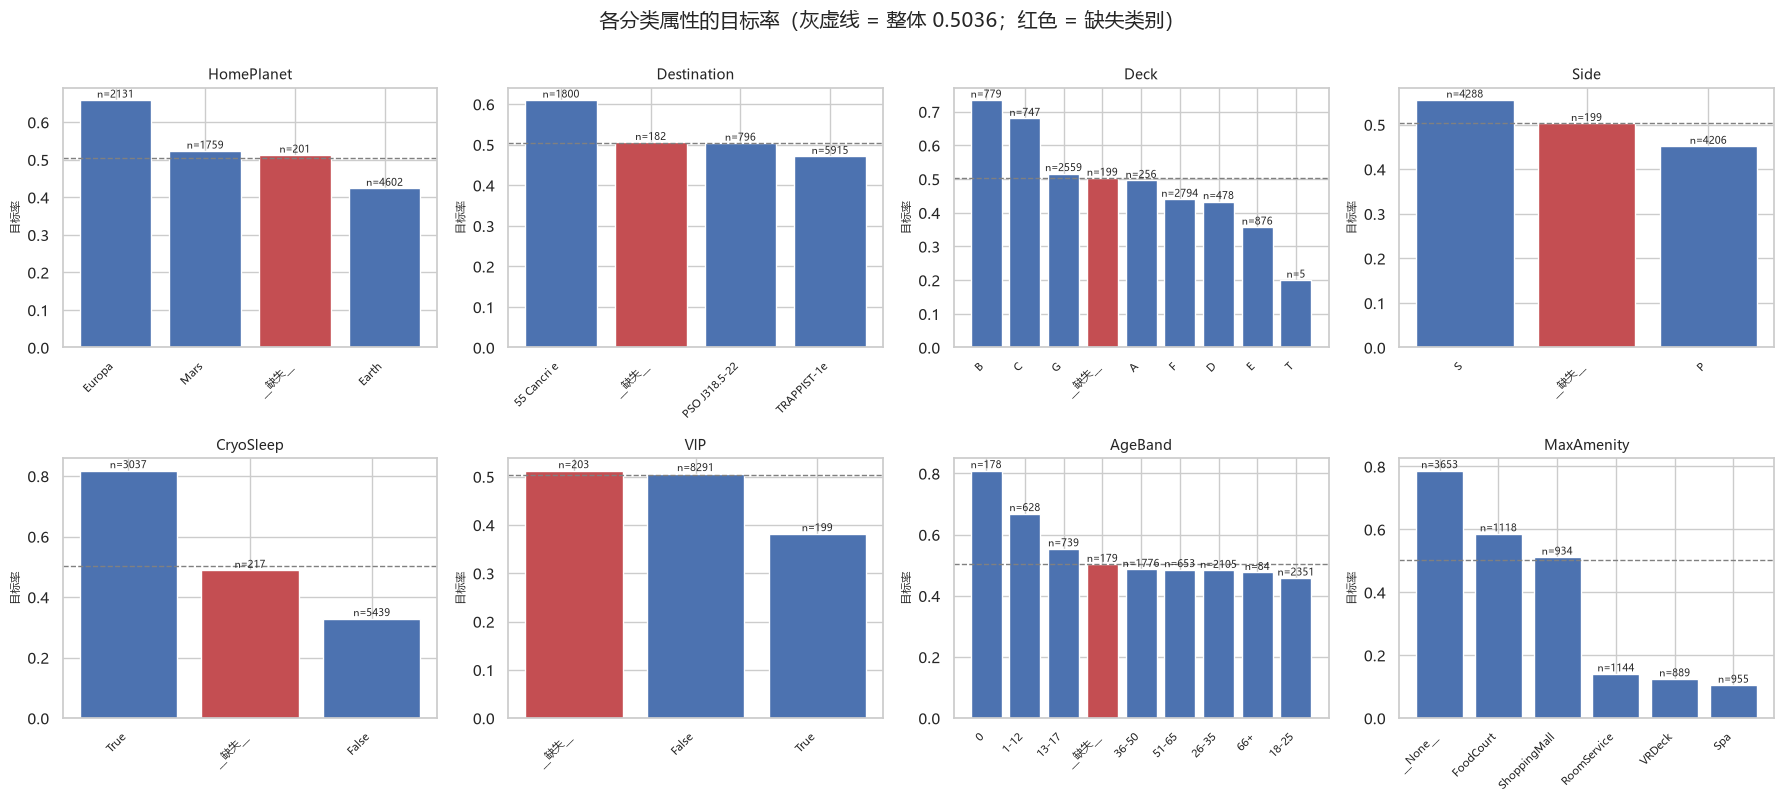

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    t = target_rate(train, col)
    order = t.index
    colors = ["#C44E52" if str(x) == "__缺失__" else "#4C72B0" for x in order]
    ax.bar(range(len(t)), t["目标率"].values, color=colors)
    ax.axhline(train[TARGET].mean(), ls="--", lw=1, color="gray")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(order, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{col}", fontsize=10)
    ax.set_ylabel("目标率", fontsize=8)
    for i, (v, n) in enumerate(zip(t["目标率"].values, t["人数"].values)):
        ax.text(i, v, f"n={n}", ha="center", va="bottom", fontsize=7)
plt.suptitle("各分类属性的目标率（灰虚线 = 整体 0.5036；红色 = 缺失类别）", y=1.0)
plt.tight_layout()
fig.savefig(FIG / "02_categorical_target_rate.png", dpi=140, bbox_inches="tight")
plt.show()



从上面能读出几条硬结论：
- **`CryoSleep` 是最强的单变量**：冷冻睡眠者目标率远高于非冷冻者。这符合剧情——
  "被传送"和"在冷冻舱"是同一件事的两面。
- `HomePlanet`、`Deck`、`Side` 有明显层次差异。
- **缺失类别的目标率都贴着 0.5036**，进一步印证缺失近似随机、信息量低。
  这一点在第 3 个 notebook 里会用实验再确认一次。



## 2.3 消费行为与目标的关系
消费列右偏严重，先看"是否消费"这种二分，再看金额分箱。
因为 `CryoSleep=True ⇒ 消费为 0`，这里要小心**混淆**：消费与目标的关系
有可能全部来自冷冻睡眠。所以最后做一次分层交叉验证这个怀疑。



In [6]:
spend_tbl = []
for col in pp.SPEND_COLS:
    used = train[col].fillna(0) > 0
    r = train.groupby(used)[TARGET].agg(目标率="mean", 人数="size")
    r["目标率"] = r["目标率"].round(4)
    r["变量"] = col
    r["是否消费"] = r.index.map({True: "有消费", False: "无消费/为0"})
    spend_tbl.append(r[["变量", "是否消费", "目标率", "人数"]])
spend_tbl = pd.concat(spend_tbl, ignore_index=True)
print("各消费项：有消费 vs 无消费")
print(spend_tbl.to_string(index=False))



各消费项：有消费 vs 无消费
          变量   是否消费    目标率   人数
 RoomService 无消费/为0 0.6278 5758
 RoomService    有消费 0.2600 2935
   FoodCourt 无消费/为0 0.5893 5639
   FoodCourt    有消费 0.3454 3054
ShoppingMall 无消费/为0 0.5969 5795
ShoppingMall    有消费 0.3171 2898
         Spa 无消费/为0 0.6345 5507
         Spa    有消费 0.2775 3186
      VRDeck 无消费/为0 0.6245 5683
      VRDeck    有消费 0.2754 3010


总消费 TotalSpend 分箱：
              目标率    人数  相对整体
_cat                         
0          0.7865  3653  1.56
1-100      0.2812    32  0.56
100-1000   0.2933  2175  0.58
1000-5000  0.2974  2196  0.59
>5000      0.3218   637  0.64


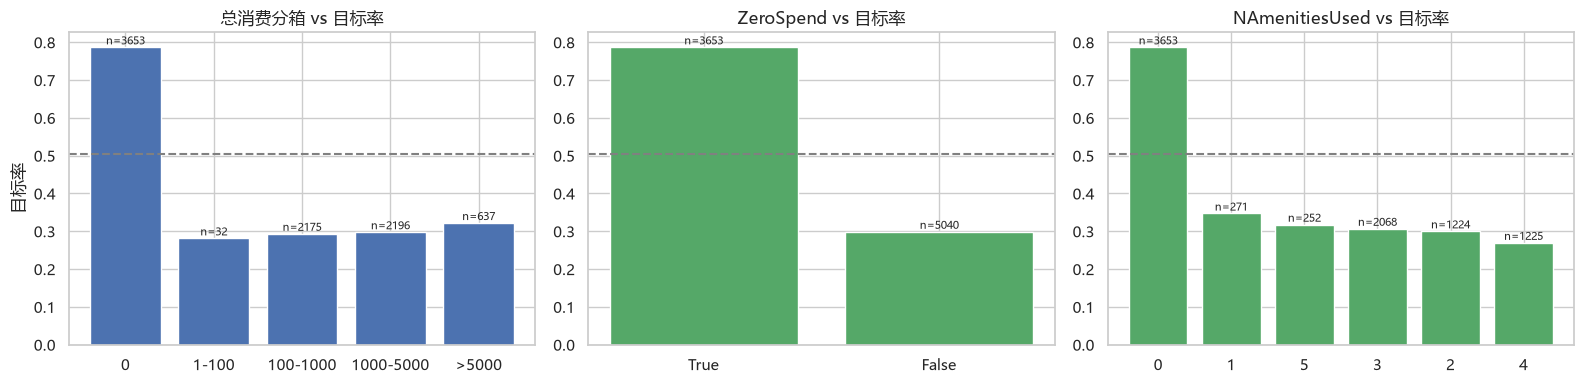

In [7]:
print("总消费 TotalSpend 分箱：")
bins = [-1, 0, 100, 1000, 5000, 1e9]
labels = ["0", "1-100", "100-1000", "1000-5000", ">5000"]
train["_spend_bin"] = pd.cut(train.TotalSpend, bins=bins, labels=labels)
print(target_rate(train, "_spend_bin").sort_index().to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t = target_rate(train, "_spend_bin").sort_index()
axes[0].bar(t.index.astype(str), t["目标率"], color="#4C72B0")
axes[0].axhline(train[TARGET].mean(), ls="--", color="gray")
axes[0].set_title("总消费分箱 vs 目标率")
axes[0].set_ylabel("目标率")
for i, (v, n) in enumerate(zip(t["目标率"], t["人数"])):
    axes[0].text(i, v, f"n={n}", ha="center", va="bottom", fontsize=8)

for ax, col in zip(axes[1:], ["ZeroSpend", "NAmenitiesUsed"]):
    t = target_rate(train, col)
    ax.bar(t.index.astype(str), t["目标率"], color="#55A868")
    ax.axhline(train[TARGET].mean(), ls="--", color="gray")
    ax.set_title(f"{col} vs 目标率")
    for i, (v, n) in enumerate(zip(t["目标率"], t["人数"])):
        ax.text(i, v, f"n={n}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "02_spend_target_rate.png", dpi=140, bbox_inches="tight")
plt.show()



### 关键检验：消费与目标的关系，是不是只因为冷冻睡眠？
把样本按 `CryoSleep` 分层，在每一层内部再看"有没有消费"与目标的关系。
如果层内差异变小甚至消失，说明消费的作用主要通过冷冻睡眠传导。



CryoSleep × 是否有消费 → 目标率：
                         目标率    人数
CryoSleep _has_spend              
False     False       0.6158   518
          True        0.2987  4921
True      False       0.8176  3037


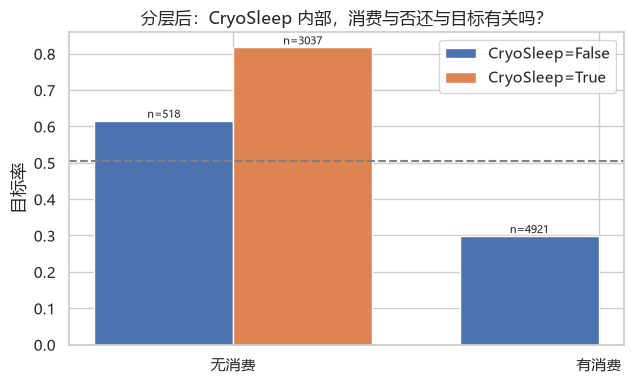

In [8]:
sub = train[train.CryoSleep.notna()].copy()
sub["_has_spend"] = sub.TotalSpend > 0
cross = (sub.groupby(["CryoSleep", "_has_spend"])[TARGET]
            .agg(目标率="mean", 人数="size").round(4))
print("CryoSleep × 是否有消费 → 目标率：")
print(cross.to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
for i, cryo in enumerate([False, True]):
    t = cross.loc[cryo]
    ax.bar(np.arange(len(t)) + i * 0.38, t["目标率"], width=0.38,
           label=f"CryoSleep={cryo}")
    for j, (v, n) in enumerate(zip(t["目标率"], t["人数"])):
        ax.text(j + i * 0.38, v, f"n={n}", ha="center", va="bottom", fontsize=8)
ax.set_xticks([0.19, 1.19])
ax.set_xticklabels(["无消费", "有消费"])
ax.axhline(train[TARGET].mean(), ls="--", color="gray")
ax.set_ylabel("目标率")
ax.set_title("分层后：CryoSleep 内部，消费与否还与目标有关吗？")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "02_cryo_spend_stratified.png", dpi=140, bbox_inches="tight")
plt.show()



## 2.4 年龄与目标



           目标率    人数  相对整体
_cat                      
0       0.8090   178  1.61
1-12    0.6688   628  1.33
13-17   0.5535   739  1.10
18-25   0.4581  2351  0.91
26-35   0.4831  2105  0.96
36-50   0.4865  1776  0.97
51-65   0.4855   653  0.96
66+     0.4762    84  0.95
__缺失__  0.5028   179  1.00


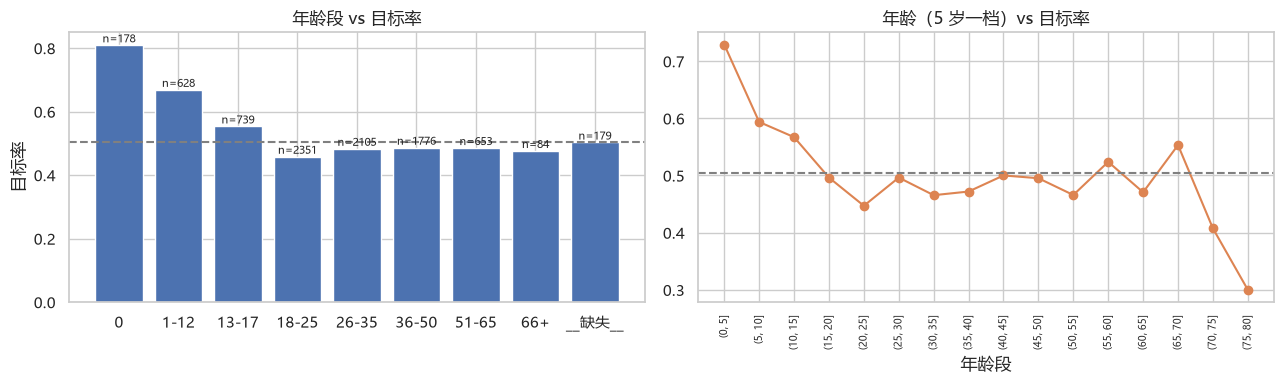

In [9]:
t = target_rate(train, "AgeBand").sort_index()
print(t.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(t.index.astype(str), t["目标率"], color="#4C72B0")
axes[0].axhline(train[TARGET].mean(), ls="--", color="gray")
axes[0].set_title("年龄段 vs 目标率")
axes[0].set_ylabel("目标率")
for i, (v, n) in enumerate(zip(t["目标率"], t["人数"])):
    axes[0].text(i, v, f"n={n}", ha="center", va="bottom", fontsize=8)

bins = np.arange(0, 85, 5)
train["_age_bin"] = pd.cut(train.Age, bins=bins)
g = train.groupby("_age_bin", observed=True)[TARGET].agg(["mean", "size"])
axes[1].plot(range(len(g)), g["mean"], "o-", color="#DD8452")
axes[1].axhline(train[TARGET].mean(), ls="--", color="gray")
axes[1].set_xticks(range(len(g)))
axes[1].set_xticklabels([str(i) for i in g.index], rotation=90, fontsize=7)
axes[1].set_title("年龄（5 岁一档）vs 目标率")
axes[1].set_xlabel("年龄段")
plt.tight_layout()
fig.savefig(FIG / "02_age_target_rate.png", dpi=140, bbox_inches="tight")
plt.show()



## 2.5 同行组效应
组大小与目标的关系，以及一个更重要的问题：
**同一个组里的人，结果是不是倾向于一致？**
这决定了本地验证能不能随机切分——如果组内高度相关，随机切分就会让
同组的人同时出现在训练和验证集，本地分数虚高。



组大小 vs 目标率：
         目标率    人数  相对整体
_cat                    
1     0.4524  4805  0.90
2     0.5380  1682  1.07
3     0.5931  1020  1.18
4     0.6408   412  1.27
5     0.5925   265  1.18
6     0.6149   174  1.22
7     0.5411   231  1.07
8     0.3942   104  0.78


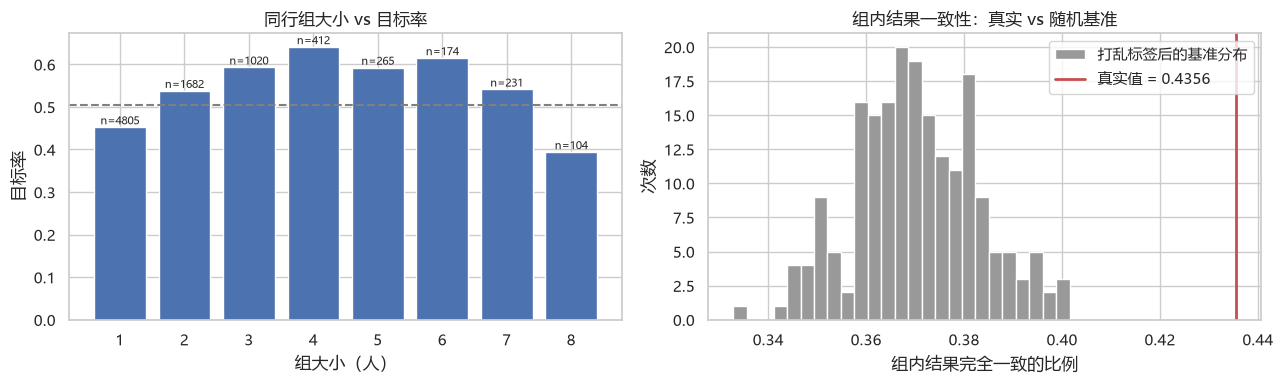

多成员组数: 1412
组内结果完全一致的比例: 0.4356
打乱标签后该比例的均值: 0.3702 (95% 区间 0.3463~0.3959)
一致组 vs 不一致组：同组平均人数 2.33 vs 3.08


In [10]:
t = target_rate(train, "GroupSize").sort_index()
print("组大小 vs 目标率：")
print(t.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(t.index.astype(int), t["目标率"], color="#4C72B0")
axes[0].axhline(train[TARGET].mean(), ls="--", color="gray")
axes[0].set_xlabel("组大小（人）")
axes[0].set_ylabel("目标率")
axes[0].set_title("同行组大小 vs 目标率")
for x, v, n in zip(t.index.astype(int), t["目标率"], t["人数"]):
    axes[0].text(x, v, f"n={n}", ha="center", va="bottom", fontsize=8)

# 组内目标一致性：多成员组里，全组结果完全相同的比例
multi = train.groupby("GroupId", observed=True).filter(lambda g: len(g) > 1)
same = multi.groupby("GroupId", observed=True)[TARGET].nunique().eq(1)
obs = same.mean()

# 基准：打乱标签（破坏组结构）后，同样统计量的分布
rng = np.random.default_rng(0)
sim = []
y = train[TARGET].values
for _ in range(200):
    shuf = pd.Series(rng.permutation(y), index=train.index)
    m = train.assign(_y=shuf).groupby("GroupId", observed=True).filter(lambda g: len(g) > 1)
    sim.append(m.groupby("GroupId", observed=True)["_y"].nunique().eq(1).mean())
sim = np.array(sim)

axes[1].hist(sim, bins=25, color="#999999", label="打乱标签后的基准分布")
axes[1].axvline(obs, color="#C44E52", lw=2, label=f"真实值 = {obs:.4f}")
axes[1].set_xlabel("组内结果完全一致的比例")
axes[1].set_ylabel("次数")
axes[1].set_title("组内结果一致性：真实 vs 随机基准")
axes[1].legend()
plt.tight_layout()
fig.savefig(FIG / "02_group_effect.png", dpi=140, bbox_inches="tight")
plt.show()

print(f"多成员组数: {same.size}")
print(f"组内结果完全一致的比例: {obs:.4f}")
print(f"打乱标签后该比例的均值: {sim.mean():.4f} (95% 区间 {np.percentile(sim, 2.5):.4f}~{np.percentile(sim, 97.5):.4f})")
print(f"一致组 vs 不一致组：同组平均人数 "
      f"{multi.groupby('GroupId', observed=True).size()[same].mean():.2f} vs "
      f"{multi.groupby('GroupId', observed=True).size()[~same].mean():.2f}")



实测结果：多成员组里"全组结果完全一致"的比例是 **0.4356**；
把标签整体打乱 200 次得到的基准分布均值 **0.3702**，95% 区间 0.3463~0.3959。
真实值落在区间之外，**组内确实存在显著的目标相关性**。
结论：**本地验证必须按组切分**（`preprocess.group_folds` 用 `StratifiedGroupKFold`），
否则同组乘客跨 fold 泄漏，本地分数会明显高于真实榜分——
在每天只有 10 次提交机会的情况下，这种虚高代价很大。



## 2.6 单变量重要性：相关性与互信息



In [11]:
num_cols = ["Age", "TotalSpend", "LogTotalSpend", "LuxurySpend", "BasicSpend",
            "NZerosAmenities", "NAmenitiesUsed", "LuxuryShare", "CabinNum",
            "GroupSize", "GroupNum", "SurnameSize", "GroupSurnameCount"]
rows = []
for c in num_cols:
    x = pd.to_numeric(train[c], errors="coerce")
    m = x.notna()
    if m.sum() < 100:
        continue
    r, p = stats.pointbiserialr(train.loc[m, TARGET].astype(int), x[m])
    rows.append({"变量": c, "点二列相关": round(r, 4), "p值": f"{p:.2e}",
                 "非空数": int(m.sum())})
corr_tbl = pd.DataFrame(rows).sort_values("点二列相关", key=abs, ascending=False)
print("数值特征与目标的相关（绝对值降序）：")
print(corr_tbl.to_string(index=False))



数值特征与目标的相关（绝对值降序）：
               变量   点二列相关        p值  非空数
    LogTotalSpend -0.4689  0.00e+00 8693
   NAmenitiesUsed -0.4402  0.00e+00 8693
  NZerosAmenities  0.4369  0.00e+00 8693
      LuxuryShare -0.3983  0.00e+00 8693
      LuxurySpend -0.2604 1.11e-134 8693
       TotalSpend -0.1995  9.38e-79 8693
        GroupSize  0.0826  1.19e-14 8693
              Age -0.0750  4.17e-12 8514
         GroupNum  0.0664  5.80e-10 8693
       BasicSpend -0.0504  2.62e-06 8693
         CabinNum -0.0451  3.21e-05 8494
GroupSurnameCount  0.0407  1.45e-04 8693
      SurnameSize -0.0322  2.70e-03 8693


互信息 Top 20：
TotalSpend                0.1368
LogTotalSpend             0.1368
LuxurySpend               0.1276
LuxuryShare               0.1230
NZerosAmenities           0.1206
ZeroSpend                 0.1199
NAmenitiesUsed            0.1177
MaxAmenity___None__       0.1154
BasicSpend                0.1082
CryoSleep                 0.1071
Spa                       0.0743
RoomService               0.0722
ShoppingMall              0.0547
VRDeck                    0.0535
MaxAmenity_Spa            0.0451
FoodCourt                 0.0347
MaxAmenity_RoomService    0.0338
MaxAmenity_VRDeck         0.0315
HomePlanet_Earth          0.0205
HomePlanet_Europa         0.0184


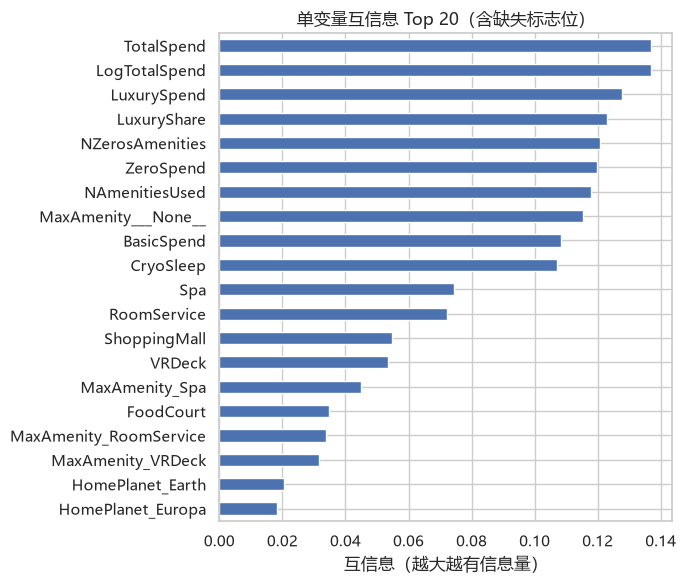

In [12]:
from sklearn.feature_selection import mutual_info_classif

X = pp.make_model_matrix(pp.Preprocessor("indicator").fit_transform(train))
mi = mutual_info_classif(X.fillna(0), train[TARGET].astype(int), random_state=0)
mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print("互信息 Top 20：")
print(mi.head(20).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
mi.head(20)[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("互信息（越大越有信息量）")
ax.set_title("单变量互信息 Top 20（含缺失标志位）")
plt.tight_layout()
fig.savefig(FIG / "02_mutual_info.png", dpi=140, bbox_inches="tight")
plt.show()



## 2.7 小结
**最强的信号**
1. `CryoSleep`：冷冻睡眠者目标率 0.8176，非冷冻者 0.3289，是最强的单变量。
2. **消费行为有独立作用，不只是冷冻睡眠的影子**。在 `CryoSleep=False` 这一层内部：
   无消费者目标率 0.6158（n=518），有消费者仅 0.2987（n=4921）——差异依然巨大。
   也就是说"花钱越多越不容易被传送"成立，与冷冻睡眠无关。
   这也解释了为什么 `LogTotalSpend` 的点二列相关（-0.4689）绝对值最大。
3. `Deck` 层次分明：B=0.7343、C=0.6801 明显高，E=0.3573 最低。
4. `HomePlanet`：Europa 0.6588 > Mars 0.5230 > Earth 0.4239。
5. `GroupSize`：单人 0.4524，2~6 人组普遍更高（4 人组 0.6408 最高）。
**弱信号 / 需谨慎**
- 各列的 `__缺失__` 类别目标率都贴近整体 0.5036（`HomePlanet` 0.5124、
  `Destination` 0.5055、`Deck` 0.5025、`Age` 0.5028），说明缺失本身几乎不携带信息。
- `VIP=True` 样本仅约 2%，`Deck='T'` 只有 5 人，单变量波动大，别过度解读。
- `TotalSpend` 原始值的相关（-0.1995）远弱于 `LogTotalSpend`（-0.4689），
  说明**必须做 log 变换**，否则这个强特征会被右偏拖弱。
**对建模的关键影响**
- 组内结果一致性 0.4356，显著高于打乱标签后的基准（均值 0.3702，
  95% 区间 0.3463~0.3959）→ **本地验证必须按组切分**（`preprocess.group_folds`）。
- 消费类特征用 `log1p` + 零值标志位，别直接用原始金额。
- 缺失指示位的预期收益有限，notebook 03 会用实验确认。
